# Context
Image classification task of assigning a label or class to an entire image.

In [ ]:
!pip install datasets

# Global Import

In [ ]:
# lOAD a storage driver in order to save best models for reuse.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# from transformers import AutoProcessor, AutoModelForImageTextToText

In [ ]:
from datasets import load_dataset
import torch
import os
from PIL import Image
from transformers.image_utils import load_image

In [ ]:
import torchvision
import torchvision.transforms as transforms

In [ ]:
from torch.utils.data import Dataset
from datasets import load_dataset
from datasets.features import Image

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch

In [ ]:
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Global Function

In [ ]:
# plot images
def imshow(img):
    img = img.cpu()
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# The model predicts that dogs with printed patterns are actually cats
def show_misclassified(net, loader, device, class_names=("Cat", "Dog"),
                       true_class=None, pred_class=None, n_images=12):
    """
    Displays examples that were misclassified.
    true_class / pred_class: class index (0=Cat, 1=Dog) to filter a specific error type.
    If None, displays all errors.
    """
    net.eval()
    mismatches = []

    with torch.inference_mode():
        for inputs, labels in loader:
            inputs_dev, labels_dev = inputs.to(device), labels.to(device)
            outputs = net(inputs_dev)
            preds = outputs.argmax(dim=1)

            for img, true, pred in zip(inputs, labels, preds.cpu()):
                if true.item() != pred.item():
                    if (true_class is None or true.item() == true_class) and \
                       (pred_class is None or pred.item() == pred_class):
                        mismatches.append((img, true.item(), pred.item()))

            if len(mismatches) >= n_images:
                break

    if not mismatches:
        print("No errors were found with these filters.")
        return

    mismatches = mismatches[:n_images]
    n_cols = 4
    n_rows = (len(mismatches) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows)
    )
    axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes

    # dé-normalisation pour affichage (inverse de Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)))
    def denorm(img):
        img = img * 0.5 + 0.5
        return img.permute(1, 2, 0).clamp(0, 1).numpy()

    for i, (img, true, pred) in enumerate(mismatches):
        axes[i].imshow(denorm(img))
        axes[i].set_title(
            f"True: {class_names[true]} | Predit: {class_names[pred]}",
            color="red"
        )
        axes[i].axis("off")

    for j in range(len(mismatches), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()


# Fonctions pour afficher en grid
def denormalize(img_tensor, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)):
    img = img_tensor.clone()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    return img.clamp(0, 1)


def show_errors(images, title, n_cols=4):
    n = len(images)
    n_rows = (n + n_cols - 1) // n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3)
    )
    axes = axes.flatten() if n > 1 else [axes]

    for i, img in enumerate(images):
        img_denorm = denormalize(img)
        axes[i].imshow(img_denorm.permute(1, 2, 0).numpy())
        axes[i].axis("off")

    for j in range(len(images), len(axes)):
        axes[j].axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def collect_misclassified(net, loader, device, class_names=("Cat", "Dog"), max_per_type=16):
    net.eval()
    errors = {"false_dog_as_cat": [], "false_cat_as_dog": []}  # (image, true, pred)

    with torch.inference_mode():
        for inputs, labels in loader:
            inputs_dev, labels_dev = inputs.to(device), labels.to(device)
            outputs = net(inputs_dev)
            preds = outputs.argmax(dim=1)

            for img, true, pred in zip(inputs, labels, preds.cpu()):
                true, pred = true.item(), pred.item()
                if true != pred:
                    if true == 1 and pred == 0:  # vrai Dog, prédit Cat
                        if len(errors["false_dog_as_cat"]) < max_per_type:
                            errors["false_dog_as_cat"].append(img)
                    elif true == 0 and pred == 1:  # vrai Cat, prédit Dog
                        if len(errors["false_cat_as_dog"]) < max_per_type:
                            errors["false_cat_as_dog"].append(img)

            # arrêt anticipé si les deux listes sont pleines
            if len(errors["false_dog_as_cat"]) >= max_per_type and len(errors["false_cat_as_dog"]) >= max_per_type:
                break

    return errors

In [ ]:
def evaluate(net, loader, criterion, device, class_names=("Cat", "Dog")):
    net.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.inference_mode():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = (np.array(all_preds) == np.array(all_labels)).mean()

    print(f"Test loss: {avg_loss:.4f}")
    print(f"Test accuracy: {accuracy:.4f}")
    print("\nClassification report:")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    print("Confusion matrix:")
    print(cm)

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "predictions": all_preds,
        "labels": all_labels,
        "confusion_matrix": cm,
    }


## Methods
Classes that encapsulate all model classes

In [ ]:
# Format the dataset
class MS_CatvsDog_HF(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        image = item["image"]
        label = item["labels"]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
class CatDogNet_1(nn.Module):
    def __init__(self):
        super().__init__()
        #format(C,H,W)
        # define a 2D convolution layer that takes 3 input channels (RGB)
        # and produces 6 output feature maps, using a 5×5 kernel
        self.conv1 = nn.Conv2d(3, 6, 5)  # input channels, output channels, kernel size

        # define a 2D max-pooling layer with kernel size 2 and stride 2
        self.pool = nn.MaxPool2d(2, 2)

        # define a second 2D convolution layer taking 6 input channels
        # and producing 16 output feature maps with a 5×5 kernel
        self.conv2 = nn.Conv2d(6, 16, 5)

        # (Difficult) define a fully-connected layer that maps the flattened feature map
        # (16 channels of size 5×5) to 120 output nodes
        # The correct input size after 224x224 input and two conv/pool layers is 16 * 53 * 53
        self.fc1 = nn.Linear(16 * 53 * 53, 120)

        # define a fully-connected layer mapping 120 nodes to 84 nodes
        self.fc2 = nn.Linear(120, 84)

        # define a final fully-connected layer mapping 84 nodes to 2 classes
        self.fc3 = nn.Linear(84, 2)

    def forward(self, x):
        # apply first convolution, ReLU activation (using F), and pooling
        x = self.pool(F.relu(self.conv1(x)))

        # apply second convolution, ReLU activation (using F), and pooling
        x = self.pool(F.relu(self.conv2(x)))

        # flatten the tensor except the batch dimension
        x = torch.flatten(x, 1)

        # apply first fully-connected layer with ReLU
        x = F.relu(self.fc1(x))

        # apply second fully-connected layer with ReLU
        x = F.relu(self.fc2(x))

        # apply final classification layer
        x = self.fc3(x)

        return x

In [ ]:
# Deep class with 6 layers
class CatDogNet_2(nn.Module):
    def __init__(self):
        super().__init__()

        # Bloc 1
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        # Bloc 2
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)

        # Bloc 3
        self.conv5 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)
        self.conv6 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn6 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)

        # Avec input 224x224 puis après 3 poolings (÷2 chacun) donc 28x28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):
        # Bloc 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        # Bloc 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        # Bloc 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# Dataset

In [ ]:
# Data set loaded from hugging face
from datasets import load_dataset

ds = load_dataset("microsoft/cats_vs_dogs")

print(ds)

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 23410
    })
})


## 1. EDA - Exploratory Data Analysis

Before preprocessing and training, we inspect the dataset size, class distribution, image characteristics and representative samples. The EDA is intentionally short and focused on aspects that can affect the classification task.

### a. Reproducibility

In [ ]:
# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


### b. Dataset overview

In [ ]:
# Dataset overview
print("Dataset:", ds)
print("Number of images:", len(ds["train"]))
print("Features:", ds["train"].features)

labels = np.array(ds["train"]["labels"])
unique, counts = np.unique(labels, return_counts=True)
label_names = {0: "Cat", 1: "Dog"}
print("\nClass distribution:")
for label, count in zip(unique, counts):
    print(f"  {label_names.get(int(label), str(label))}: {count} ({100*count/len(labels):.2f}%)")


Dataset: DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 23410
    })
})
Number of images: 23410
Features: {'image': Image(mode=None, decode=True), 'labels': ClassLabel(names=['cat', 'dog'])}

Class distribution:
  Cat: 11741 (50.15%)
  Dog: 11669 (49.85%)


### c. Image characteristics

In [ ]:
# Image characteristics: inspect a representative subset to keep EDA lightweight
from collections import Counter

sample_n = min(1000, len(ds["train"]))
widths, heights, modes = [], [], []
for i in range(sample_n):
    img = ds["train"][i]["image"]
    widths.append(img.width)
    heights.append(img.height)
    modes.append(img.mode)

print(f"Inspected images: {sample_n}/{len(ds['train'])}")
print(f"Width:  min={min(widths)}, max={max(widths)}, mean={np.mean(widths):.1f}")
print(f"Height: min={min(heights)}, max={max(heights)}, mean={np.mean(heights):.1f}")
print("Image modes:", Counter(modes))


Inspected images: 1000/23410
Width:  min=50, max=500, mean=417.1
Height: min=50, max=500, mean=361.8
Image modes: Counter({'RGB': 1000})


### d. Class distribution plot

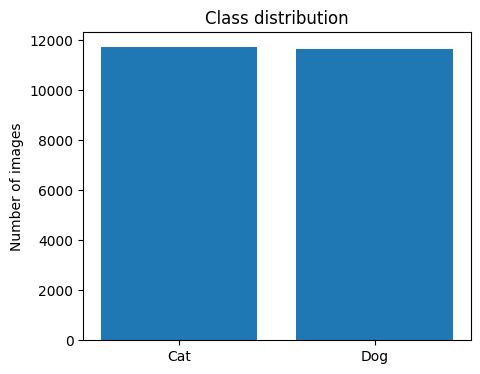

In [ ]:
# Class distribution plot
plt.figure(figsize=(5, 4))
plt.bar([label_names.get(int(x), str(x)) for x in unique], counts)
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.show()


### e. Representative samples from both classes

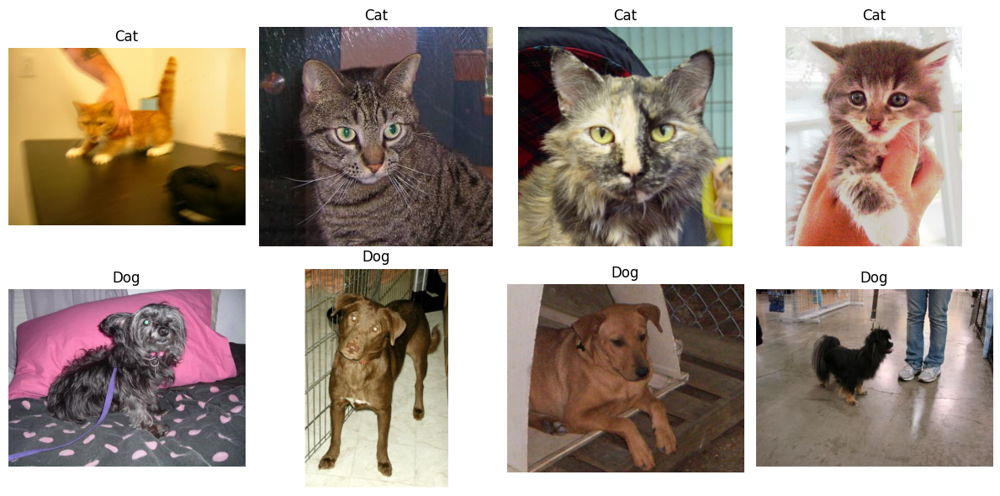

In [ ]:
# Representative samples from both classes
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, label in enumerate([0, 1]):
    indices = np.where(labels == label)[0][:4]
    for col, idx in enumerate(indices):
        axes[row, col].imshow(ds["train"][int(idx)]["image"])
        axes[row, col].axis("off")
        axes[row, col].set_title(label_names[int(label)])
plt.tight_layout()
plt.show()


### EDA takeaway
- The task is binary image classification (cat vs. dog).
- The class counts are reported above.

This step made it possible to verify whether the imbalance between classes is likely to introduce bias in the accuracy.
In fact:
- the images have different dimensions,
so standardization is necessary following this pipeline: RGB → resizing/cropping → tensor → normalization.

## 2. Transform dataset : Standardize

The output of torchvision datasets are PILImage images of range \[0,
1\]. We transform them to Tensors of normalized range \[-1, 1\].
 >**Why transforming data from -1 to 1?**
>* Neural networks learn best when the inputs are roughly centered around 0 (ReLU, Optimizers...)
 >* Gradient behaviour is better when values aren’t all positive
>* Many pretrained models in torchvision (ResNet, VGG, etc.) expect inputs that were normalized to mean around 0


### Satndardization n°1

In [ ]:

transform = transforms.Compose(
  [
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # (moyennes), (écarts-types) pour chaque canal
  ]
)

batch_size = 4

In [ ]:
trainset = MS_CatvsDog_HF(ds["train"], transform=transform)


## 3. Showing images before/after transform

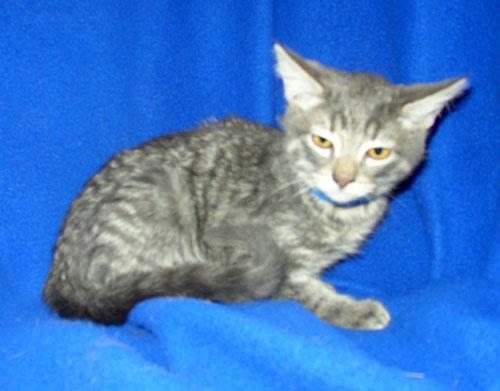

In [ ]:
# Show image before transform
ds['train'][41]['image']

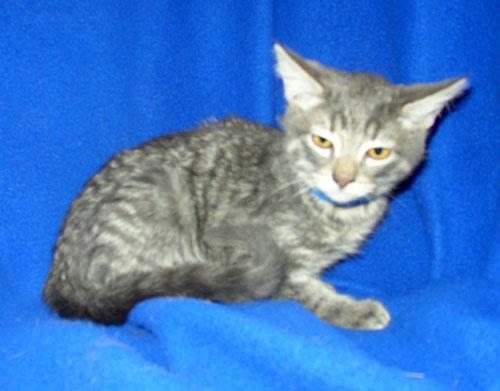

In [ ]:
# SHOW image after transform

trainset.dataset[41]['image']

# Device Setting

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda', index=0)

#### utilise vLLM pour parallelisé sur les gpu avec un senario de ce qui s'execute sur le cpu et celui sur le GPU

# Model loading

## Train flow
>* load data
>* feed forward
>* loss calculation
>* backward
>* optimise params

## Pre trained model

This model is large and taking time to finetune. We dropped off this idea because we have ressource limitation.

In [ ]:
# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# # Load images
# # image1 = load_image("https://cdn.britannica.com/61/93061-050-99147DCE/Statue-of-Liberty-Island-New-York-Bay.jpg")
# # image2 = load_image("https://huggingface.co/spaces/merve/chameleon-7b/resolve/main/bee.jpg")

# # Initialize processor and model
# processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct")
# model = AutoModelForImageTextToText.from_pretrained(
#     "HuggingFaceTB/SmolVLM-Instruct",
#     torch_dtype=torch.bfloat16,
#     _attn_implementation="flash_attention_2" if DEVICE == "cuda" else "eager",
# ).to(DEVICE)

# # Create input messages
# messages = [
#     {
#         "role": "user",
#         "content": [
#             {"type": "image"},
#             {"type": "image"},
#             {"type": "text", "text": "Can you describe the two images?"}
#         ]
#     },
# ]

# # Prepare inputs
# prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
# inputs = processor(text=prompt, images=[ds['train'][40]['image'], ds['train'][4]['image']], return_tensors="pt")
# inputs = inputs.to(DEVICE)

# # Generate outputs
# generated_ids = model.generate(**inputs, max_new_tokens=500)
# generated_texts = processor.batch_decode(
#     generated_ids,
#     skip_special_tokens=True,
# )

# print(generated_texts[0])


model.safetensors: reconstructing file:   0%|          |  0.00B / 4.49GB            

model.safetensors: downloading bytes:           |  0.00B            

## Split dataset

In [ ]:
from torch.utils.data import random_split

# Use `random_split` to split 70%  15% and 15% trainset, valset and 15%
# Transform any splited dataset to  torch dataset throw dataloader

#################
train_size = int(0.7 * len(trainset))
val_size = int(0.15 * len(trainset))
test_size = len(trainset) - train_size - val_size
trainset, valset,testset = random_split(trainset, [train_size, val_size,test_size], generator=torch.Generator().manual_seed(SEED))
#################

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
valloader = torch.utils.data.DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

# Models

## Net Training 1

with naive stoped criteria

### 1. Baseline - CatDogNet_1 + SGD


In [ ]:
writer = SummaryWriter('./runs/cnn')

net = CatDogNet_1().to(device) #intancied and set up device
criterion = nn.CrossEntropyLoss() #
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

print_every = max(1, len(trainloader) // 5)
epoch = 0
previous_loss = float('inf')
stop_training = False
while True:# loop over the dataset multiple times
    epoch += 1
    running_loss = 0.0
    epoch_loss_sum = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        epoch_loss_sum += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader) + i)
            running_loss = 0.0

    current_loss = epoch_loss_sum / len(trainloader)
    if current_loss > previous_loss:
        print(
            f"Arrêt : loss précédent = {previous_loss:.3f}, "
            f"loss courant = {current_loss:.3f}"
        )
        stop_training = True

    previous_loss = current_loss
    # Validation loss calculation after each epoch
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    if stop_training:
        break

print('Finished Training')
writer.close()

[1,   819] loss: 0.689
[1,  1638] loss: 0.682
[1,  2457] loss: 0.657
[1,  3276] loss: 0.648
[1,  4095] loss: 0.623
Epoch 1 validation loss: 0.611
[2,   819] loss: 0.600
[2,  1638] loss: 0.587
[2,  2457] loss: 0.584
[2,  3276] loss: 0.564
[2,  4095] loss: 0.543
Epoch 2 validation loss: 0.572
[3,   819] loss: 0.511
[3,  1638] loss: 0.501
[3,  2457] loss: 0.511
[3,  3276] loss: 0.502
[3,  4095] loss: 0.478
Epoch 3 validation loss: 0.518
[4,   819] loss: 0.388
[4,  1638] loss: 0.401
[4,  2457] loss: 0.389
[4,  3276] loss: 0.409
[4,  4095] loss: 0.408
Epoch 4 validation loss: 0.585
[5,   819] loss: 0.238
[5,  1638] loss: 0.238
[5,  2457] loss: 0.280
[5,  3276] loss: 0.287
[5,  4095] loss: 0.296
Epoch 5 validation loss: 0.597
[6,   819] loss: 0.113
[6,  1638] loss: 0.159
[6,  2457] loss: 0.176
[6,  3276] loss: 0.160
[6,  4095] loss: 0.196
Epoch 6 validation loss: 0.687
[7,   819] loss: 0.092
[7,  1638] loss: 0.113
[7,  2457] loss: 0.120
[7,  3276] loss: 0.112
[7,  4095] loss: 0.121
Epoch 7 v

#### Save model

In [ ]:
save_dir = '/content/drive/MyDrive/Colab Notebooks/Models'
os.makedirs(save_dir, exist_ok=True)
torch.save(net.state_dict(), f'{save_dir}/best_model_naiveStoped.pt')

## Net Training 2
with the right stop as soon as possible

### Parametres

In [ ]:
net = CatDogNet_1().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

### 2. Controlled improvement naive Early stopping

We want to improve early stopping approach by trying to put it on validation set to see if there is improvement

In [ ]:
writer = SummaryWriter('./runs/cnn_2')

print_every = max(1, len(trainloader) // 5)

patience = 3          # nombre d'époques tolérées sans amélioration
min_delta = 0.0        # amélioration minimale considérée comme significative
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # sauvegarde du meilleur modèle
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Recharger le meilleur modèle avant évaluation finale
net.load_state_dict(torch.load('best_model.pt'))

[1,   819] loss: 0.692
[1,  1638] loss: 0.670
[1,  2457] loss: 0.646
[1,  3276] loss: 0.625
[1,  4095] loss: 0.617
Epoch 1 validation loss: 0.593
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,   819] loss: 0.562
[2,  1638] loss: 0.573
[2,  2457] loss: 0.567
[2,  3276] loss: 0.549
[2,  4095] loss: 0.527
Epoch 2 validation loss: 0.534
  -> nouvelle meilleure val_loss, modèle sauvegardé
[3,   819] loss: 0.466
[3,  1638] loss: 0.458
[3,  2457] loss: 0.458
[3,  3276] loss: 0.461
[3,  4095] loss: 0.464
Epoch 3 validation loss: 0.497
  -> nouvelle meilleure val_loss, modèle sauvegardé
[4,   819] loss: 0.327
[4,  1638] loss: 0.356
[4,  2457] loss: 0.365
[4,  3276] loss: 0.355
[4,  4095] loss: 0.368
Epoch 4 validation loss: 0.537
  -> pas d'amélioration (1/3)
[5,   819] loss: 0.184
[5,  1638] loss: 0.206
[5,  2457] loss: 0.213
[5,  3276] loss: 0.239
[5,  4095] loss: 0.237
Epoch 5 validation loss: 0.606
  -> pas d'amélioration (2/3)
[6,   819] loss: 0.118
[6,  1638] loss: 0.129
[6,  245

<All keys matched successfully>

#### Save model

In [ ]:
save_dir = '/content/drive/MyDrive/Colab Notebooks/Models'
os.makedirs(save_dir, exist_ok=True)
torch.save(net.state_dict(), f'{save_dir}/best_modelCorrectEarlyStoped.pt')



## Final evaluation and error analysis


### Test the network on the test data

#### 1. Load best Model

In [ ]:
net = CatDogNet_1().to(device)
net.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/Models/best_model_naiveStoped.pt'))
net.eval()

CatDogNet_1(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=44944, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

#### 2. Evaluation complète (accuracy, precision, recall, F1, matrice de confusion)



In [ ]:
test_results = evaluate(net, testloader, criterion, device)

Test loss: 1.5673
Test accuracy: 0.7386

Classification report:
              precision    recall  f1-score   support

         Cat       0.73      0.75      0.74      1732
         Dog       0.75      0.73      0.74      1780

    accuracy                           0.74      3512
   macro avg       0.74      0.74      0.74      3512
weighted avg       0.74      0.74      0.74      3512

Confusion matrix:
[[1292  440]
 [ 478 1302]]


# Analyse des résultats du Test set

**Configuration évaluée :** CatDogNet_1 (LeNet-5 adapté), SGD (lr=0.001, momentum=0.9), 2 époques, cats_vs_dogs.

## Résultats globaux

Le modèle atteint une **accuracy de 73.86%** sur le test set (3512 échantillons), pour une **loss de 1.5673**. Ce niveau se situe nettement au-dessus du hasard (50%), confirmant que le modèle a appris une représentation discriminante des deux classes, mais reste loin des performances attendues (>90%).

## Analyse par classe

| Classe | Precision | Recall | F1-score | Support |
| ------ | --------- | ------ | -------- | ------- |
| Cat    | 0.73      | 0.75   | 0.74     | 1732    |
| Dog    | 0.75      | 0.73   | 0.74     | 1780    |

Le comportement du modèle est **asymétrique** entre les deux classes :

* **Recall Cat (0.75) > Recall Dog (0.73)** : le modèle détecte correctement 75% des vrais chats, mais seulement 73% des vrais chiens. Une proportion significative de chiens est classée à tort comme chats.

* **Precision Dog (0.75) > Precision Cat (0.73)** : lorsque le modèle prédit "chien", il a raison dans 75% des cas ; lorsqu'il prédit "chat", il n'a raison que dans 73% des cas, cohérent avec le biais observé dans la matrice de confusion.

## Matrice de confusion

|              | Prédit Cat | Prédit Dog |
| ------------ | ---------- | ---------- |
| **Vrai Cat** | 1292 (VP)  | 440 (FN)   |
| **Vrai Dog** | 478 (FN)   | 1302 (VP)  |

Le nombre de chiens mal classés comme chats (478) est **1.09× supérieur** au nombre de chats mal classés comme chiens (440). Le modèle présente donc un **léger biais en faveur de la classe "Cat"**, indépendamment d'un déséquilibre de classes dans le test set (1732 vs 1780, ratio quasi équilibré à 1.03:1), ce qui exclut le déséquilibre des classes comme cause principale de cette asymétrie.

## En bref

* Accuracy macro-moyenne = accuracy pondérée (0.74 = 0.74), confirmant l'absence de déséquilibre significatif entre classes dans le test set.

* L'écart F1 entre classes est nul (0.74 vs 0.74, Δ=0.00), ce qui indique des performances globalement similaires entre les deux classes.

* La loss de test (1.5673) est nettement supérieure à la loss de validation observée en fin d'entraînement (0.528–0.545). Cette différence indique que, malgré une accuracy relativement stable, le modèle généralise moins bien sur le test set en termes de loss, ce qui peut suggérer une moins bonne calibration des probabilités ou une sensibilité à certaines prédictions fortement erronées.

Test loss: 1.5673
Test accuracy: 0.7386

Classification report:

```text
              precision    recall  f1-score   support

         Cat       0.73      0.75      0.74      1732
         Dog       0.75      0.73      0.74      1780

    accuracy                           0.74      3512
   macro avg       0.74      0.74      0.74      3512
weighted avg       0.74      0.74      0.74      3512
```

Confusion matrix:

```text
[[1292  440]
 [ 478 1302]]
```


### Causes possibles des erreurs observées


**1. Sous-apprentissage (underfitting) du modèle**

CatDogNet_1 est une architecture peu profonde (2 couches convolutives, LeNet-5), avec une capacité de représentation limitée pour une tâche aussi complexe visuellement que cats vs dogs (contrairement à MNIST/CIFAR pour lequel LeNet-5 a été conçu).

**2. Résolution/prétraitement des images**

Le pipeline utilise Resize(256) + CenterCrop(224), mais si CatDogNet_1 attend une entrée compatible avec **16** * **5** * **5**  en sortie de conv2 (soit une image d'entrée ~32×32), il y a une incohérence dimensionnelle entre le prétraitement et l'architecture. Mais on remarque que le modèle a malgré tout tourné, cela signifie soit que l'architecture a été adaptée en conséquence, soit qu'un redimensionnement implicite a eu lieu  dans les deux cas, une image 224×224 compressée à travers seulement 2 couches conv/pool perd énormément de détails fins qui distinguent chats et chiens (texture du pelage, forme des oreilles, museau par exemple).

**3. Asymétrie intrinsèque au dataset**

Variance intra-classe plus élevée chez les chiens : le dataset contient une grande diversité de races de chiens (formes, tailles, couleurs, postures) par rapport aux chats, qui présentent une morphologie plus homogène.

Alors un modèle peu profond peut avoir du mal à capturer cette diversité, et confondre les chiens aux traits atypiques (petites races, couleurs proches des chats) avec des chats.
Chevauchement visuel de certaines races : chiens à poils courts, oreilles pointues, ou petite taille (ex. chihuahuas, certains terriers) partagent des traits visuels avec des chats, ce qui augmente la confusion dans ce sens plutôt que l'inverse.

**4. Bruit et qualité du dataset microsoft/cats_vs_dogs**
Après quelques recherche, il est avéré que ce data
ce dataset est connu pour contenir des images corrompues, mal étiquetées ou de mauvaise qualité (bruit d'étiquetage). Un mauvais label systématiquement orienté (plus de chiens mal étiquetés "chat" que l'inverse, par exemple) peut directement causer ce biais.
Présence d'images avec plusieurs animaux,humain,objets, arrière-plans complexes, ou occlusions partielles  plus difficiles à interpréter pour un petit réseau.

**5. Biais d'initialisation et dynamique d'apprentissage**

Avec un seed fixe et peu d'itérations, le modèle peut converger vers une frontière de décision légèrement décalée vers une classe selon l'ordre d'exposition aux exemples pendant les premiers batches (effet plus marqué avec un lr faible et peu d'époques).
momentum=0.9 accentue l'effet des premières directions de gradient apprises  un déséquilibre précoce (même mineur) tend à se renforcer.

### Quelques verification avant de tester les hypothèses

#### 1. Mismatch image de chien predit comme chat

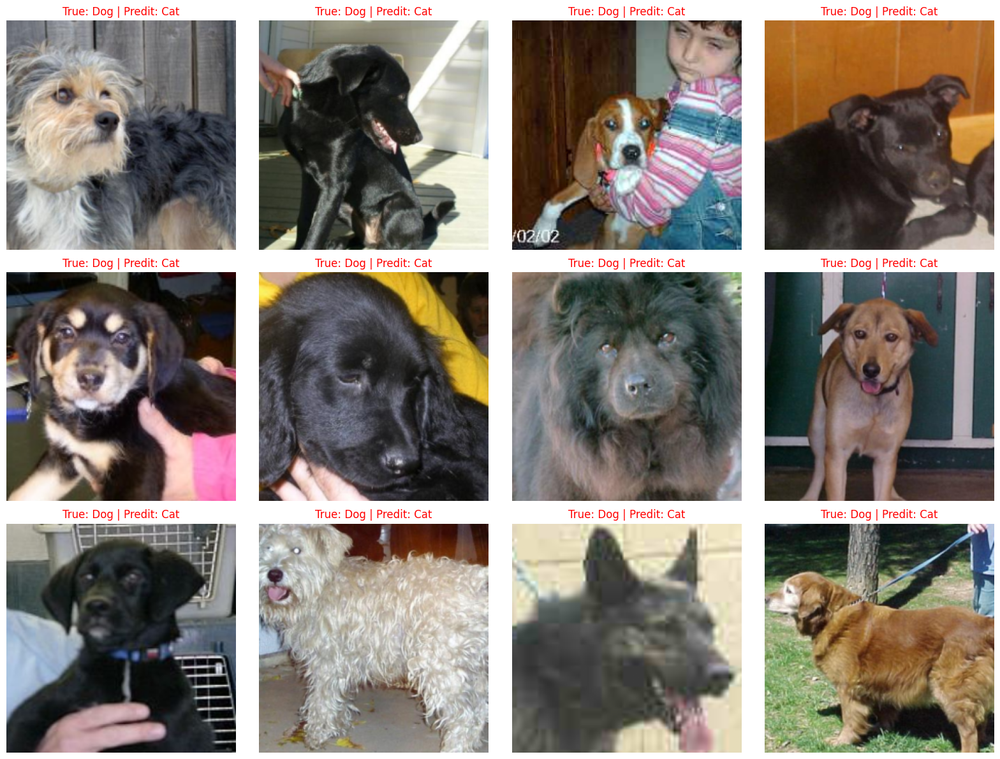

In [ ]:
# The most common case in your confusion matrix: e.g 12 dogs misclassified as cats
show_misclassified(net, testloader, device, true_class=1, pred_class=0, n_images=12)

#### 2. Execution cats vs dogs

In [ ]:
show_misclassified(net, testloader, device, true_class=0, pred_class=0, n_images=12)

Dogs predicted as cats: 16 examples displayed


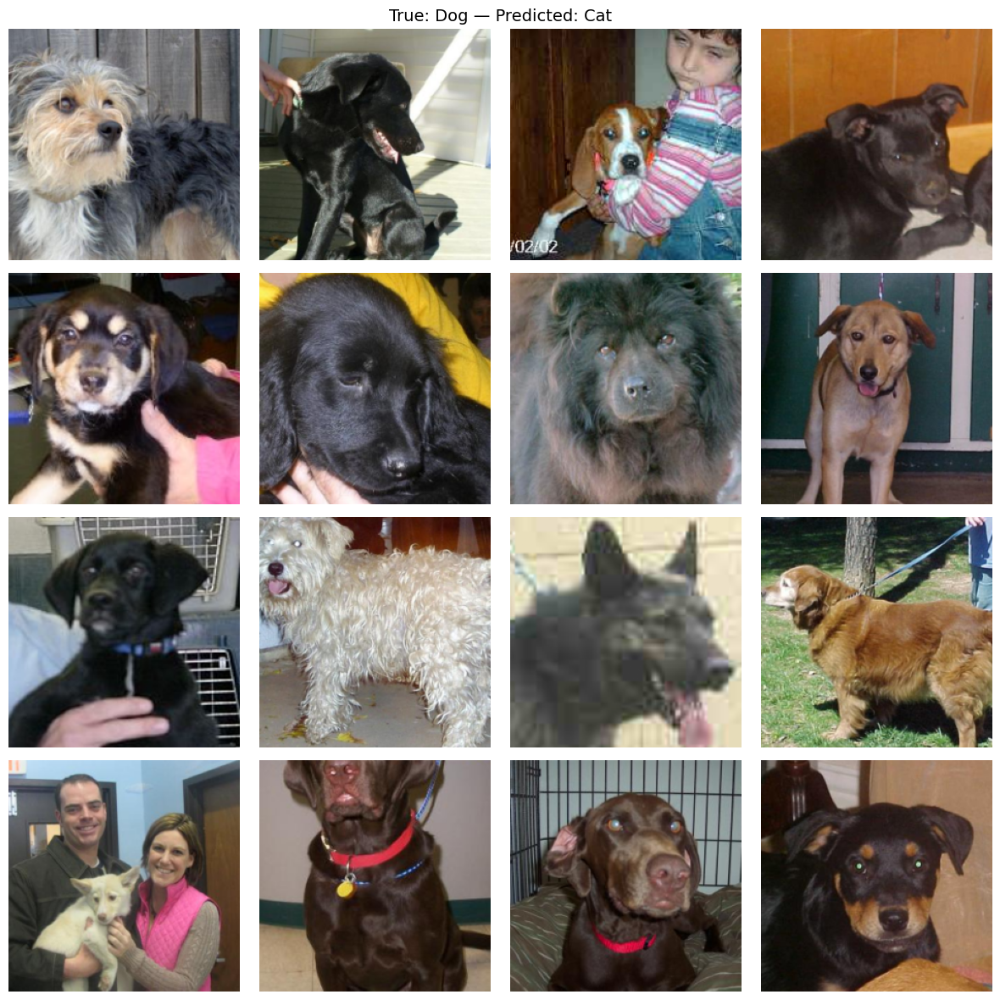

Cats predicted as dogs: 16 examples displayed


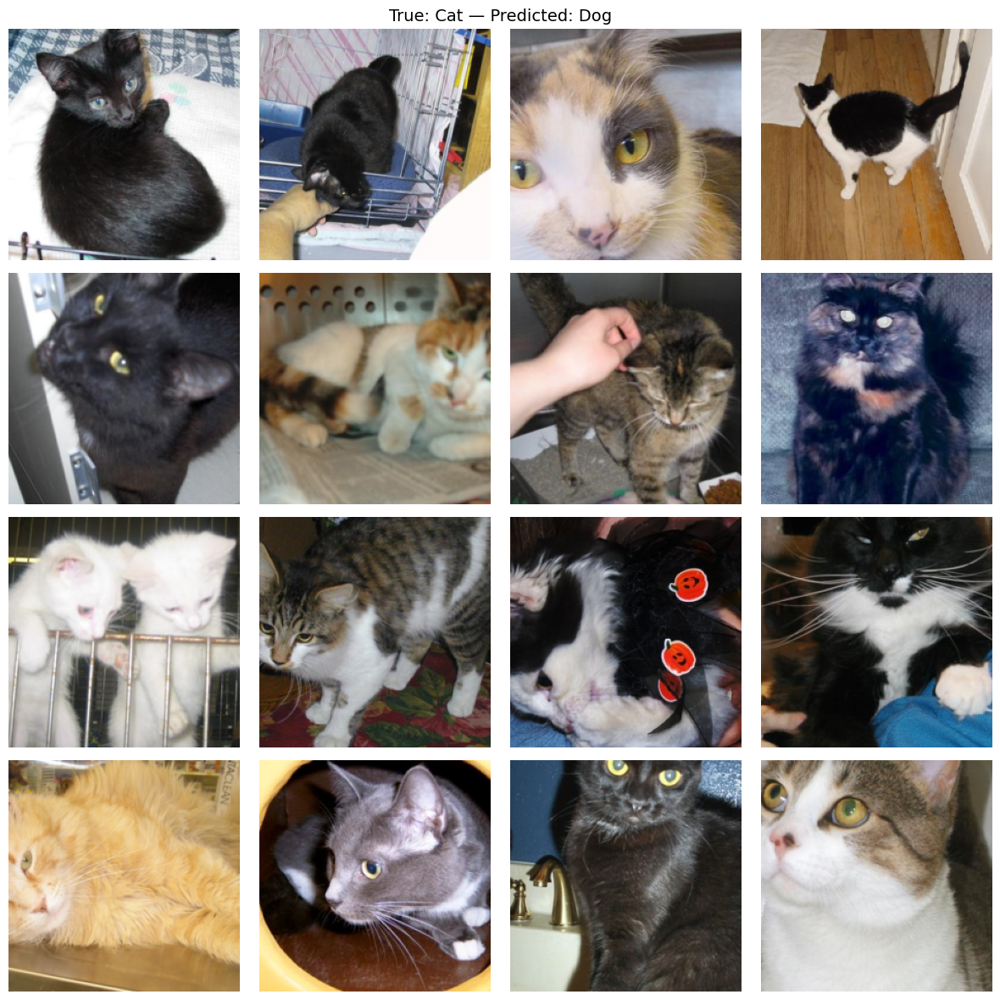

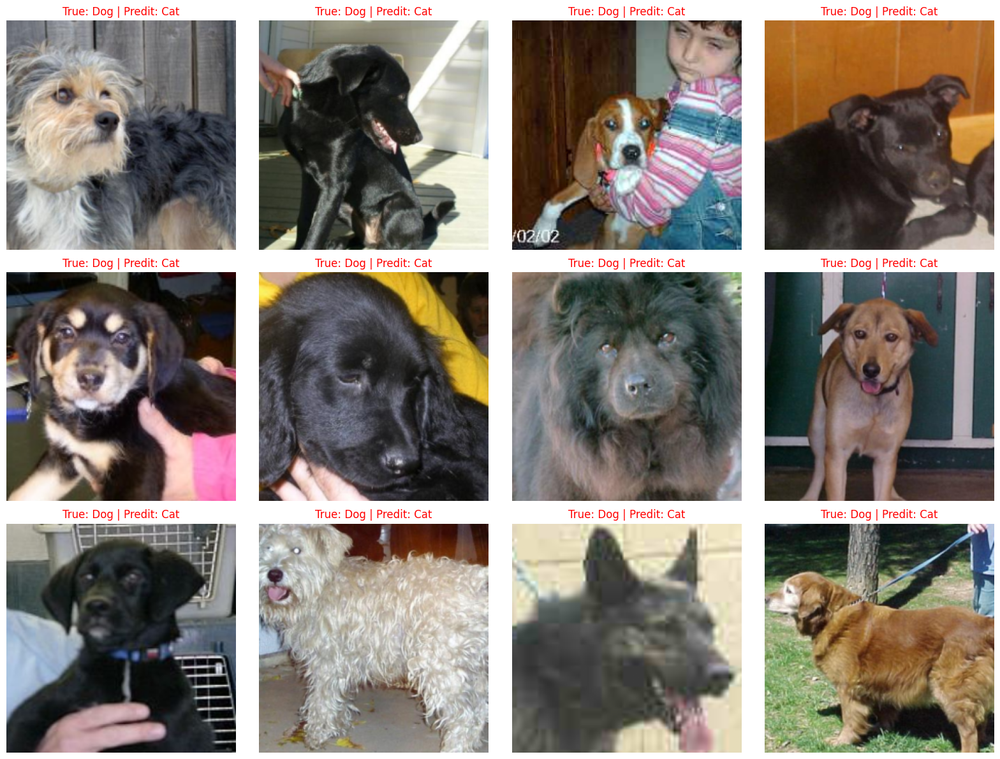

In [ ]:
errors = collect_misclassified(net, testloader, device, max_per_type=16)

print(f"Dogs predicted as cats: {len(errors['false_dog_as_cat'])} examples displayed")
show_errors(errors['false_dog_as_cat'], 'True: Dog — Predicted: Cat')

print(f"Cats predicted as dogs: {len(errors['false_cat_as_dog'])} examples displayed")
show_errors(errors["false_cat_as_dog"], "True: Cat — Predicted: Dog")
show_misclassified(net, testloader, device, true_class=1, pred_class=0, n_images=12)

## Verification of Hypotheses

### 1.  Reason 1: Shallow Convolutional Network

 ## A. Creating a New Deep Network

**Reason**

1. **BatchNorm:** to stabilize training when the network is deeper (prevents activation explosions or vanishing, as discussed in class; I’m not sure if this actually happens, but I’m implementing it as a precaution),
2. **Dropout:** With more parameters, the risk of overfitting increases, hence the use of Dropout.

3. **Padding=1 with a 3×3 kernel:** Keep the spatial size constant in each block; only MaxPool2d reduces the resolution.
4. **batchsize:** 4 (default)

### 1. Controlled Improvement of Net 1 – A Deeper CNN Architecture

* Adding more layer(CatDogNet_2:6)
  * lr=0.001
  * momentum=0.9
  * SGD optimizer
  * **batchsize:** 4




#### 1.1.  Execution

In [ ]:
writer = SummaryWriter('./runs/cnn_deep-0')

net= CatDogNet_2().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

print_every = max(1, len(trainloader) // 5)

patience = 3
min_delta = 0.0
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # sauvegarde du meilleur modèle
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Recharger le meilleur modèle avant évaluation finale
net.load_state_dict(torch.load('best_model.pt'))

[1,   819] loss: 0.768
[1,  1638] loss: 0.694
[1,  2457] loss: 0.695
[1,  3276] loss: 0.693
[1,  4095] loss: 0.694
Epoch 1 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,   819] loss: 0.693
[2,  1638] loss: 0.694
[2,  2457] loss: 0.693
[2,  3276] loss: 0.694
[2,  4095] loss: 0.693
Epoch 2 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[3,   819] loss: 0.693
[3,  1638] loss: 0.694
[3,  2457] loss: 0.694
[3,  3276] loss: 0.694
[3,  4095] loss: 0.693
Epoch 3 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[4,   819] loss: 0.693
[4,  1638] loss: 0.694
[4,  2457] loss: 0.693
[4,  3276] loss: 0.693
[4,  4095] loss: 0.694
Epoch 4 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[5,   819] loss: 0.694
[5,  1638] loss: 0.693
[5,  2457] loss: 0.694
[5,  3276] loss: 0.693
[5,  4095] loss: 0.694
Epoch 5 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[6,   819]

<All keys matched successfully>

#### 1.2. Save model

In [ ]:
torch.save(net.state_dict(), '/content/drive/MyDrive/Colab Notebooks/Models/best_model_deepNew-0.pt')

### Evaluate on testset

In [ ]:
net = CatDogNet_2().to(device)
net.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/Models/best_model_deepNew-0.pt'))
net.eval()

CatDogNet_2(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running

In [ ]:
test_results = evaluate(net, testloader, criterion, device)

Test loss: 0.6936
Test accuracy: 0.4932

Classification report:
              precision    recall  f1-score   support

         Cat       0.49      1.00      0.66      1732
         Dog       0.00      0.00      0.00      1780

    accuracy                           0.49      3512
   macro avg       0.25      0.50      0.33      3512
weighted avg       0.24      0.49      0.33      3512

Confusion matrix:
[[1732    0]
 [1780    0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Note 1
The network isn't learning at all—the loss remains stuck at ~0.693 = ln(2), which is exactly the theoretical loss of a model that predicts randomly or uniformly across two classes. After 12 epochs, this isn't a matter of patience; it's a structural training issue.

Our solution will be:
1. Increase the learning rate slightly
2. Change the optimizer (optimizer = optim.Adam(net.parameters(), lr=1e-3))

### Augmentation du learning rate

### 2. Controlled improvement net 2(CatDogNet_2) - Optimizer / learning-rate experiments
* 6 layers(CatDogNet_2)
  * lr=0.01
  * momentum=0.9
  * SGD optimizer
  * **batchsize:** 4


In [ ]:
writer = SummaryWriter('./runs/cnn_deep-0.1')

net= CatDogNet_2().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

print_every = max(1, len(trainloader) // 5)

patience = 3
min_delta = 0.0
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # save best model
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Reload the best model before the final evaluation
net.load_state_dict(torch.load('best_model.pt'))

[1,   819] loss: 3.184
[1,  1638] loss: 0.697
[1,  2457] loss: 0.698
[1,  3276] loss: 0.695
[1,  4095] loss: 0.695
Epoch 1 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,   819] loss: 0.697
[2,  1638] loss: 0.696
[2,  2457] loss: 0.698
[2,  3276] loss: 0.697
[2,  4095] loss: 0.695
Epoch 2 validation loss: 0.707
  -> pas d'amélioration (1/3)
[3,   819] loss: 0.696
[3,  1638] loss: 0.696
[3,  2457] loss: 0.696
[3,  3276] loss: 0.697
[3,  4095] loss: 0.697
Epoch 3 validation loss: 0.695
  -> pas d'amélioration (2/3)
[4,   819] loss: 0.696
[4,  1638] loss: 0.697
[4,  2457] loss: 0.696
[4,  3276] loss: 0.696
[4,  4095] loss: 0.696
Epoch 4 validation loss: 0.694
  -> pas d'amélioration (3/3)
Early stopping déclenché après 4 époques.
Finished Training


<All keys matched successfully>

### Note 2
No improvement,loss still egal to  **0.6**

### 3. Controlled improvement net 2(CatDogNet_2) - Optimizer  experiments
* 6 layers(CatDogNet_2)
  * lr=0.01
  * adam optimizer

In [ ]:
writer = SummaryWriter('./runs/cnn_deep-0.2')

net= CatDogNet_2().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=1e-3)

print_every = max(1, len(trainloader) // 5)

patience = 3
min_delta = 0.0
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # sauvegarde du meilleur modèle
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Recharger le meilleur modèle avant évaluation finale
net.load_state_dict(torch.load('best_model.pt'))

[1,   819] loss: 1.408
[1,  1638] loss: 0.694
[1,  2457] loss: 0.694
[1,  3276] loss: 0.693
[1,  4095] loss: 0.693
Epoch 1 validation loss: 0.693
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,   819] loss: 0.693
[2,  1638] loss: 0.693
[2,  2457] loss: 0.694
[2,  3276] loss: 0.693
[2,  4095] loss: 0.693
Epoch 2 validation loss: 0.693
  -> pas d'amélioration (1/3)
[3,   819] loss: 0.693
[3,  1638] loss: 0.693
[3,  2457] loss: 0.693
[3,  3276] loss: 0.696
[3,  4095] loss: 0.696
Epoch 3 validation loss: 0.693
  -> pas d'amélioration (2/3)
[4,   819] loss: 0.693
[4,  1638] loss: 0.693
[4,  2457] loss: 0.693
[4,  3276] loss: 0.699
[4,  4095] loss: 0.693
Epoch 4 validation loss: 0.693
  -> pas d'amélioration (3/3)
Early stopping déclenché après 4 époques.
Finished Training


<All keys matched successfully>

### Note 3
No improvement.

There could be several reasons, but let's check these hypotheses.
* Is the network capable of perfectly learning a small dataset when given the same examples multiple times?
* Does the error signal from the loss function propagate correctly to the network’s parameters?
* Is the problem that the model is unable to learn from multiple different batches of data, even though it may be able to memorize a single batch?

### Checking hypotheses

#### 1. Overfitting a single batch

In [ ]:
net = CatDogNet_2().to(device)
optimizer = optim.Adam(net.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


inputs, labels = next(iter(trainloader))
inputs, labels = inputs.to(device), labels.to(device)
print("Labels dans le batch:", labels)

net.train()
for i in range(200):
    optimizer.zero_grad()
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    if i % 20 == 0:
        print(f"iter {i}: loss={loss.item():.4f}")

Labels dans le batch: tensor([0, 0, 1, 1], device='cuda:0')
iter 0: loss=0.7275
iter 20: loss=0.0000
iter 40: loss=0.0000
iter 60: loss=0.0000
iter 80: loss=0.0000
iter 100: loss=0.0000
iter 120: loss=0.0000
iter 140: loss=0.0000
iter 160: loss=0.0000
iter 180: loss=0.0000


#### 2. Checking Gradients

In [ ]:
#Check the actual gradients after a backward()
nputs, labels = next(iter(trainloader))
inputs, labels = inputs.to(device), labels.to(device)

net.train()
optimizer.zero_grad()
outputs = net(inputs)
loss = criterion(outputs, labels)
loss.backward()

for name, param in net.named_parameters():
    if param.grad is not None:
        print(f"{name}: grad mean abs = {param.grad.abs().mean().item():.8f}")
    else:
        print(f"{name}: NO GRADIENT (None)")

conv1.weight: grad mean abs = 8.14703846
conv1.bias: grad mean abs = 0.00000189
bn1.weight: grad mean abs = 1.63036907
bn1.bias: grad mean abs = 1.06082678
conv2.weight: grad mean abs = 1.43604732
conv2.bias: grad mean abs = 0.00000016
bn2.weight: grad mean abs = 0.97240651
bn2.bias: grad mean abs = 0.46879640
conv3.weight: grad mean abs = 0.47389323
conv3.bias: grad mean abs = 0.00000006
bn3.weight: grad mean abs = 0.33955842
bn3.bias: grad mean abs = 0.20792559
conv4.weight: grad mean abs = 0.24064851
conv4.bias: grad mean abs = 0.00000004
bn4.weight: grad mean abs = 0.25158685
bn4.bias: grad mean abs = 0.16710795
conv5.weight: grad mean abs = 0.10999896
conv5.bias: grad mean abs = 0.00000002
bn5.weight: grad mean abs = 0.13895783
bn5.bias: grad mean abs = 0.15824288
conv6.weight: grad mean abs = 0.09681386
conv6.bias: grad mean abs = 0.00000004
bn6.weight: grad mean abs = 1.64665556
bn6.bias: grad mean abs = 0.96239585
fc1.weight: grad mean abs = 0.00517198
fc1.bias: grad mean abs =

#### 3. Learning from the first 20 batches

In [ ]:

# Learning from the first 20 batches on DataLoader
net.train()
for i, (inputs, labels) in enumerate(trainloader):
    inputs, labels = inputs.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    print(f"batch {i}: loss={loss.item():.4f}")
    if i >= 20:
        break

batch 0: loss=35.9192
batch 1: loss=68.9867
batch 2: loss=12.6057
batch 3: loss=88.3481
batch 4: loss=0.0000
batch 5: loss=0.0000
batch 6: loss=41.7204
batch 7: loss=70.3169
batch 8: loss=54.9294
batch 9: loss=0.6812
batch 10: loss=15.3918
batch 11: loss=35.3805
batch 12: loss=42.9393
batch 13: loss=87.8733
batch 14: loss=25.0682
batch 15: loss=34.6392
batch 16: loss=6.9167
batch 17: loss=11.9581
batch 18: loss=10.8968
batch 19: loss=14.2958
batch 20: loss=58.2645


### Hypothesis Note

We observe:

1. **Learning from a single batch:** The loss drops from 0.7275 to 0.0000 as early as iteration 20. The model is therefore able to perfectly memorize a small batch. This indicates that the forward pass, the loss, and the learning process are working.

2. **Gradients:** Gradients are present for all parameters. Therefore, there is no issue with gradient propagation. However, the sometimes very high values,notably fc2.weight = 20.47 show that the gradients can be very large.

3. **Multiple Batches:** The loss is highly unstable and reaches extremely high values (88.35, 87.87, etc.), with a few batches at 0.0000. The model therefore learns from certain batches, but its learning is unstable from one batch to the next.


In summary, the problem stems neither from a lack of gradients nor from the model’s inability to learn. The fact that it memorizes one batch but produces highly variable loss values across different batches suggests primarily a problem with the stability of the optimization process.

### Show some images

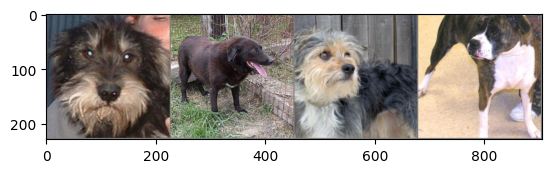

GroundTruth:  Dog            Dog            Dog            Dog           


In [ ]:
classes=['Cat','Dog']
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print("GroundTruth: ", ' '.join(f'{classes[labels[j]]:14s}' for j in range(4)))

### 4. Controlled improvement of any t net (CatDogNet_1 and CatDogNet_2) / sensitivity check - Batch size too small
 * Rebatchses
    * 4 to 64
 * re-split


#### 1. Rebatchses and re-split

In [ ]:
batch_size=64
trainloader_2 = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
valloader_2 = torch.utils.data.DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)
testloader_2 = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

#### 2. Train sur le reseau 1 classique

Batch size modified from 4 to 64 on baseline model
* CrossEntropyLoss
* lr=0.001, momentum=0.9
* optimizer: optim.SGD

In [ ]:
writer = SummaryWriter('./runs/cnn-02')

net= CatDogNet_1().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

print_every = max(1, len(trainloader_2) // 5)

patience = 3
min_delta = 0.0
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader_2, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader_2) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader_2:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader_2)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # sauvegarde du meilleur modèle
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Recharger le meilleur modèle avant évaluation finale
net.load_state_dict(torch.load('best_model.pt'))

[1,    51] loss: 0.693
[1,   102] loss: 0.692
[1,   153] loss: 0.691
[1,   204] loss: 0.689
[1,   255] loss: 0.688
Epoch 1 validation loss: 0.687
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,    51] loss: 0.684
[2,   102] loss: 0.682
[2,   153] loss: 0.678
[2,   204] loss: 0.674
[2,   255] loss: 0.672
Epoch 2 validation loss: 0.663
  -> nouvelle meilleure val_loss, modèle sauvegardé
[3,    51] loss: 0.663
[3,   102] loss: 0.658
[3,   153] loss: 0.661
[3,   204] loss: 0.657
[3,   255] loss: 0.647
Epoch 3 validation loss: 0.639
  -> nouvelle meilleure val_loss, modèle sauvegardé
[4,    51] loss: 0.644
[4,   102] loss: 0.633
[4,   153] loss: 0.641
[4,   204] loss: 0.625
[4,   255] loss: 0.628
Epoch 4 validation loss: 0.629
  -> nouvelle meilleure val_loss, modèle sauvegardé
[5,    51] loss: 0.626
[5,   102] loss: 0.612
[5,   153] loss: 0.611
[5,   204] loss: 0.624
[5,   255] loss: 0.610
Epoch 5 validation loss: 0.608
  -> nouvelle meilleure val_loss, modèle sauvegardé
[6,    51]

<All keys matched successfully>

#### Evaluation CNN Classique(CatDogNet_1)

In [ ]:
res=evaluate(net, testloader_2, criterion, device)

Test loss: 0.5459
Test accuracy: 0.7332

Classification report:
              precision    recall  f1-score   support

         Cat       0.74      0.72      0.73      1732
         Dog       0.73      0.75      0.74      1780

    accuracy                           0.73      3512
   macro avg       0.73      0.73      0.73      3512
weighted avg       0.73      0.73      0.73      3512

Confusion matrix:
[[1241  491]
 [ 446 1334]]


##### Save


In [ ]:
torch.save(net.state_dict(), '/content/drive/MyDrive/Colab Notebooks/Models/best_modelNew_2.pt')

#### 2. Train  deep net 2(CatDogNet_2)

Batch size modified from 4 to 64 on the deeper model
* CrossEntropyLoss
* lr=0.001, momentum=0.9
* optimizer: optim.SGD

In [ ]:
writer = SummaryWriter('./runs/cnn_deep-0.2')

net= CatDogNet_2().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

print_every = max(1, len(trainloader_2) // 5)

patience = 3
min_delta = 0.0
best_val_loss = float('inf')
epochs_no_improve = 0
epoch = 0

while True:
    epoch += 1

    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader_2, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % print_every == print_every - 1:
            print(f'[{epoch}, {i + 1:5d}] loss: {running_loss / print_every:.3f}')
            writer.add_scalar('training loss', running_loss / print_every, epoch * len(trainloader_2) + i)
            running_loss = 0.0

    # Validation
    net.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for data in valloader_2:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(valloader_2)
    print(f'Epoch {epoch} validation loss: {avg_val_loss:.3f}')
    writer.add_scalar('validation loss', avg_val_loss, epoch)

    # Early stopping logic
    if avg_val_loss < best_val_loss - min_delta:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')  # save best model
        print(f'  -> nouvelle meilleure val_loss, modèle sauvegardé')
    else:
        epochs_no_improve += 1
        print(f'  -> pas d\'amélioration ({epochs_no_improve}/{patience})')

    if epochs_no_improve >= patience:
        print(f'Early stopping déclenché après {epoch} époques.')
        break

print('Finished Training')
writer.close()

# Reload the best model before the final evaluation
net.load_state_dict(torch.load('best_model.pt'))

[1,    51] loss: 0.727
[1,   102] loss: 0.640
[1,   153] loss: 0.622
[1,   204] loss: 0.600
[1,   255] loss: 0.603
Epoch 1 validation loss: 0.616
  -> nouvelle meilleure val_loss, modèle sauvegardé
[2,    51] loss: 0.571
[2,   102] loss: 0.547
[2,   153] loss: 0.533
[2,   204] loss: 0.547
[2,   255] loss: 0.517
Epoch 2 validation loss: 0.490
  -> nouvelle meilleure val_loss, modèle sauvegardé
[3,    51] loss: 0.497
[3,   102] loss: 0.480
[3,   153] loss: 0.491
[3,   204] loss: 0.478
[3,   255] loss: 0.474
Epoch 3 validation loss: 0.448
  -> nouvelle meilleure val_loss, modèle sauvegardé
[4,    51] loss: 0.459
[4,   102] loss: 0.443
[4,   153] loss: 0.440
[4,   204] loss: 0.457
[4,   255] loss: 0.431
Epoch 4 validation loss: 0.466
  -> pas d'amélioration (1/3)
[5,    51] loss: 0.417
[5,   102] loss: 0.433
[5,   153] loss: 0.407
[5,   204] loss: 0.414
[5,   255] loss: 0.409
Epoch 5 validation loss: 0.447
  -> nouvelle meilleure val_loss, modèle sauvegardé
[6,    51] loss: 0.404
[6,   102

<All keys matched successfully>

#### Evaluation DEEP net(CatDogNet_2)

In [ ]:
res=evaluate(net, testloader_2, criterion, device)

Test loss: 0.3755
Test accuracy: 0.8462

Classification report:
              precision    recall  f1-score   support

         Cat       0.83      0.86      0.85      1732
         Dog       0.86      0.83      0.85      1780

    accuracy                           0.85      3512
   macro avg       0.85      0.85      0.85      3512
weighted avg       0.85      0.85      0.85      3512

Confusion matrix:
[[1490  242]
 [ 298 1482]]


##### Save

In [ ]:
torch.save(net.state_dict(), '/content/drive/MyDrive/Colab Notebooks/Models/best_model_deepNew-01.pt')

##### Les erreurs

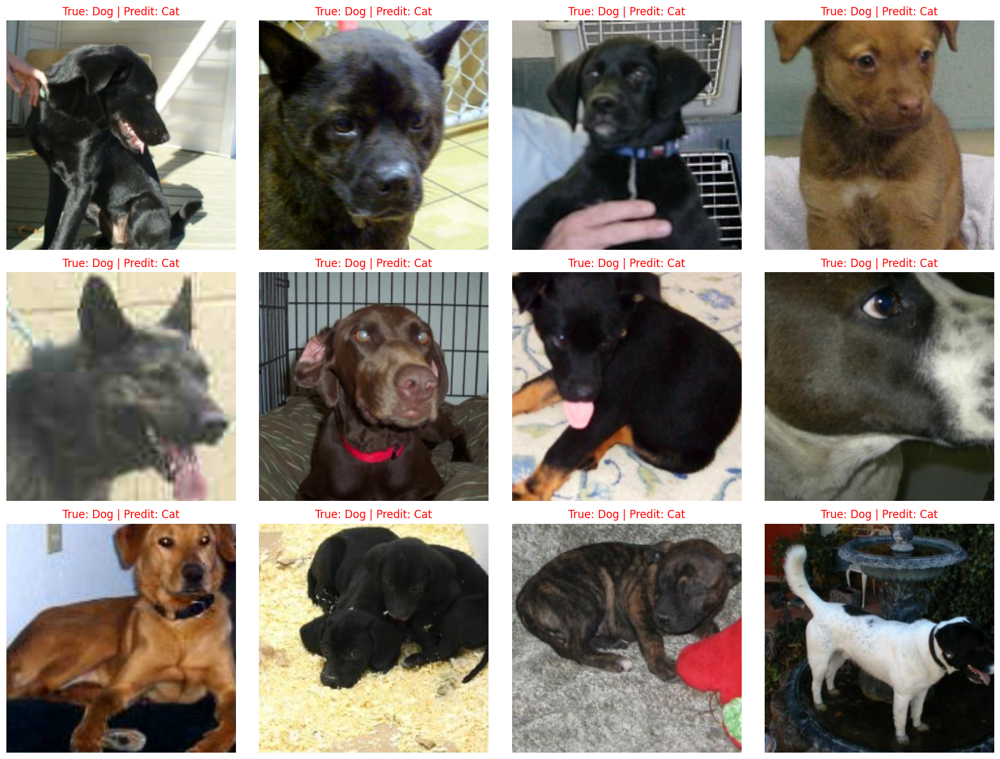

In [ ]:
# Dog but predit cat
show_misclassified(net, testloader_2, device, true_class=1, pred_class=0, n_images=12)

In [ ]:
# cat but predict dog
errors = collect_misclassified(net, testloader_2, device, max_per_type=16)

print(f"Chiens prédits comme chats : {len(errors['false_dog_as_cat'])} exemples affichés")
show_errors(errors["false_dog_as_cat"], "Vrai: Dog — Prédit: Cat")

print(f"Chats prédits comme chiens : {len(errors['false_cat_as_dog'])} exemples affichés")
show_errors(errors["false_cat_as_dog"], "Vrai: Cat — Prédit: Dog")


# Comparison table

| Experiment | Main change | Purpose |
|---|---|---|
| Baseline | CatDogNet_1 + SGD, lr=0.001 | Reference performance |
| Improvement 1 | Validation-based early stopping | Reduce unnecessary training / select best epoch |
| Improvement 2 | CatDogNet_2 (deeper + BatchNorm) | Test whether a more expressive CNN improves representation |
| Improvement 3 | Learning rate / optimizer (SGD vs Adam) | Test optimization sensitivity |
| Sensitivity check | Batch size 4 → 64 | Test the effect of batch size while keeping the task unchanged |



# DASHBOARD

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "./runs"

<IPython.core.display.Javascript object>

In [ ]:
log_dir = "/content/drive/MyDrive//content/drive/MyDrive/Colab Notebooks/Models/logs"
writer = SummaryWriter(log_dir)